In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/telco_customer_churn_clean.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [7]:
churn_counts = df['Churn'].value_counts()
churn_per = (df['Churn'].value_counts(normalize=True)*100).round(3)
print(churn_counts)
print(churn_per)

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.463
1    26.537
Name: proportion, dtype: float64


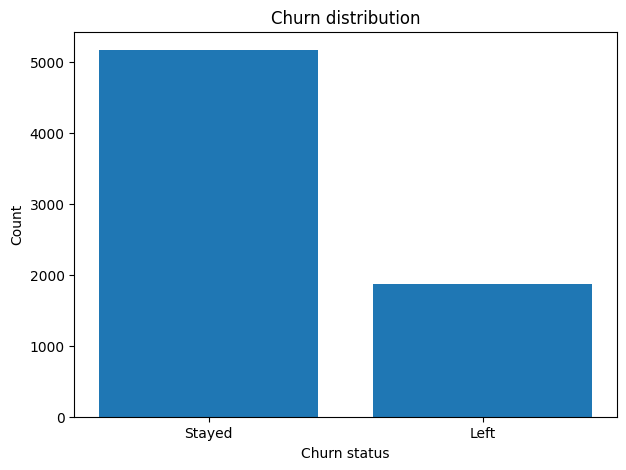

In [8]:
import matplotlib.pyplot as plt
labels = ['Stayed', 'Left']
counts = [ (df['Churn']==0).sum(), (df['Churn']==1).sum() ]
plt.figure(figsize=(7,5))
plt.bar(labels, counts)
plt.title('Churn distribution')
plt.xlabel('Churn status')
plt.ylabel('Count')
plt.show()

Churn : Target variable analysis
0 : people who stayed
1 : people who left

The churn percentage is 
Retention rate : 73.46%
Churn rate : 26.54%


So the class is imbalanced.(For evaluation metrics)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [12]:

numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

df[numerical_features].describe()


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


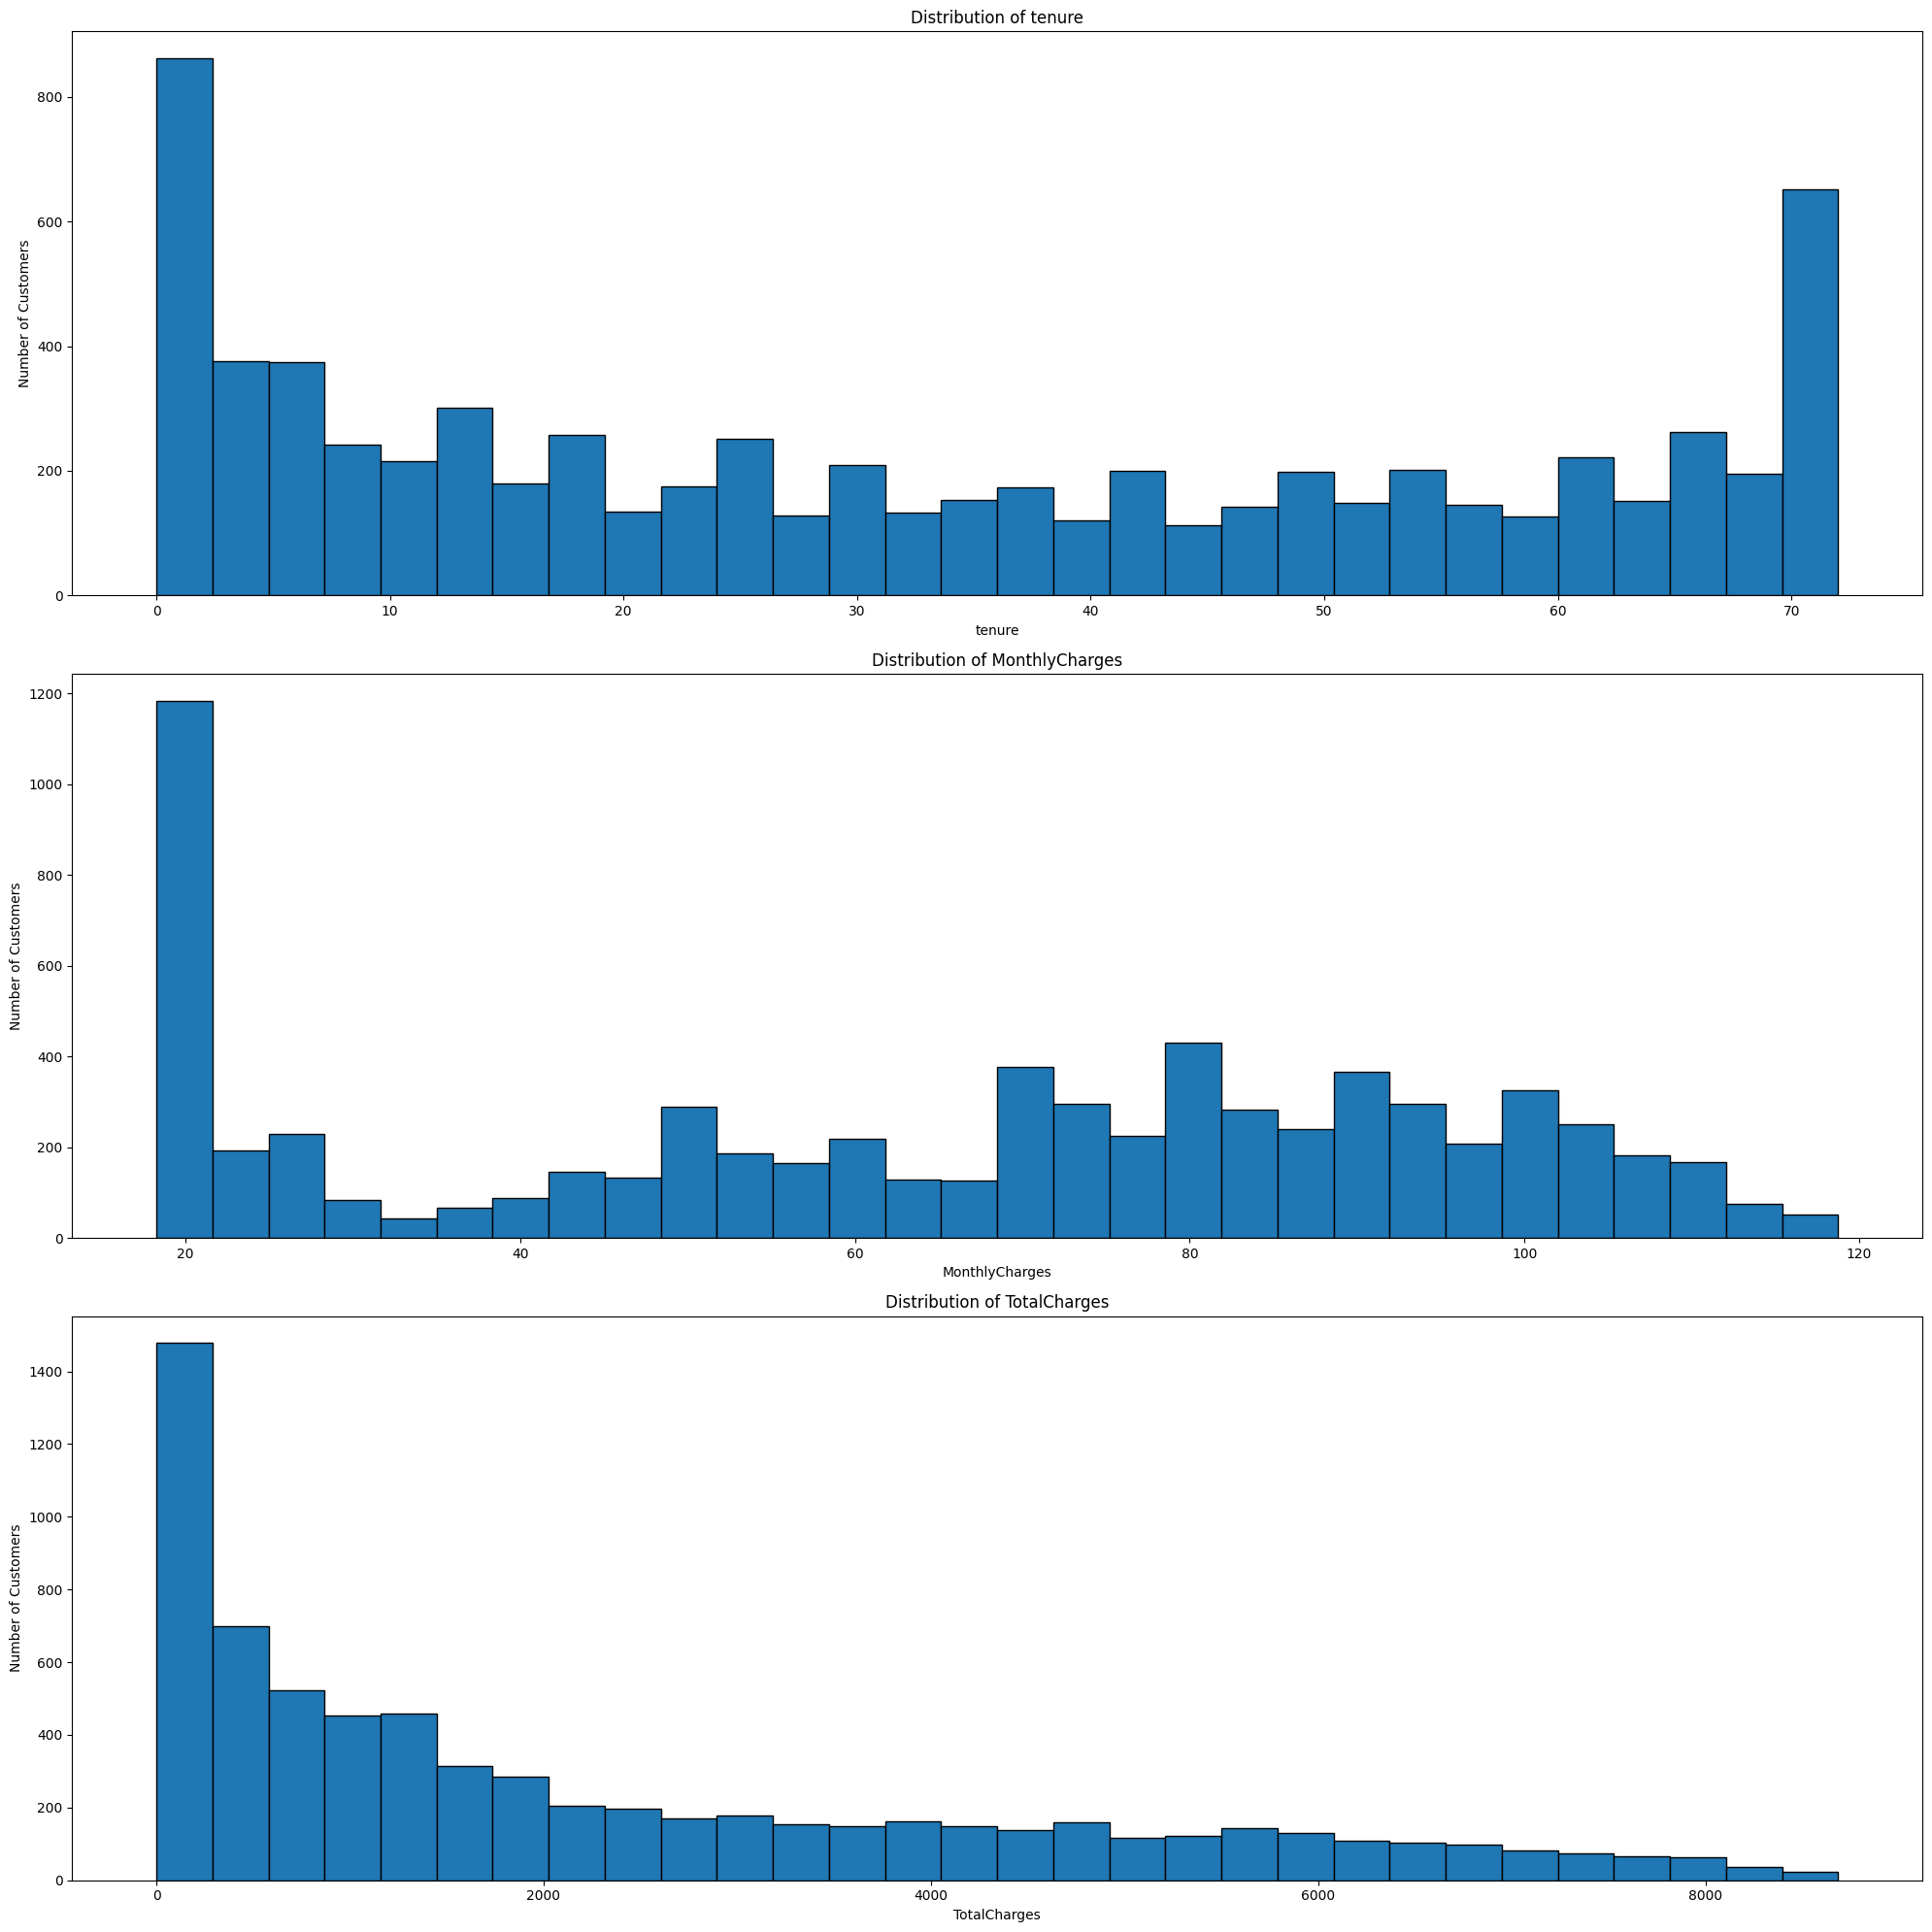

In [17]:

import matplotlib.pyplot as plt

numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(3, 1, figsize=(20, 20))

for ax, feature in zip(axes, numerical_features):
    ax.hist(df[feature], bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


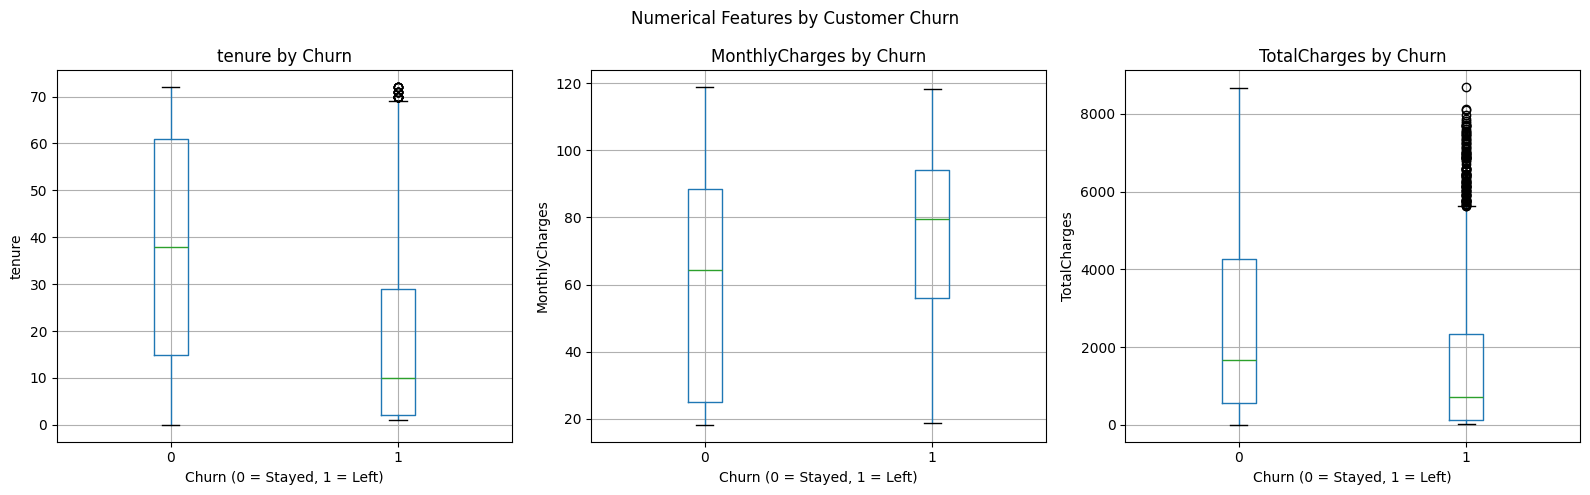

In [19]:

import matplotlib.pyplot as plt

numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, numerical_features):
    df.boxplot(column=feature, by="Churn", ax=ax)
    ax.set_title(f"{feature} by Churn")
    ax.set_xlabel("Churn (0 = Stayed, 1 = Left)")
    ax.set_ylabel(feature)

plt.suptitle("Numerical Features by Customer Churn")
plt.tight_layout()
plt.show()


In [20]:

# Count customers by contract type and churn status
contract_counts = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print("Customer counts by contract and churn:")
display(contract_counts)

# Calculate churn rate within each contract type
contract_churn_rate = (
    df.groupby("Contract")["Churn"].mean() * 100
)

print("\nChurn rate by contract type (%):")
display(contract_churn_rate.round(2))


Customer counts by contract and churn:


Churn,0,1
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



Churn rate by contract type (%):


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

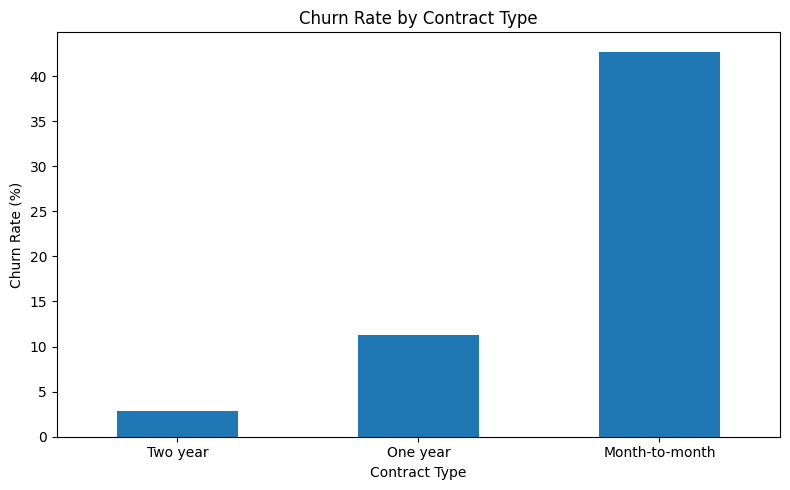

In [21]:

contract_churn_rate.sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [22]:
internet_churn_rate = (
    df.groupby("InternetService")["Churn"].mean() * 100
)

print("Churn rate by Internet Service (%):")
display(internet_churn_rate.round(2))

Churn rate by Internet Service (%):


InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

In [23]:
payment_churn_rate = (
    df.groupby("PaymentMethod")["Churn"].mean() * 100
)

print("Churn rate by Payment Method (%):")
display(payment_churn_rate.round(2))

Churn rate by Payment Method (%):


PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64

In [24]:
paperless_churn_rate = (
    df.groupby("PaperlessBilling")["Churn"].mean() * 100
)

print("Churn rate by Paperless Billing (%):")
display(paperless_churn_rate.round(2))

Churn rate by Paperless Billing (%):


PaperlessBilling
No     16.33
Yes    33.57
Name: Churn, dtype: float64

In [25]:
security_churn_rate = (
    df.groupby("OnlineSecurity")["Churn"].mean() * 100
)

print("Churn rate by Online Security (%):")
display(security_churn_rate.round(2))

Churn rate by Online Security (%):


OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: Churn, dtype: float64

In [27]:
tech_support_churn_rate = (
    df.groupby("TechSupport")["Churn"].mean() * 100
)

print("Churn rate by Tech Support (%):")
display(tech_support_churn_rate.round(2))

Churn rate by Tech Support (%):


TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Churn, dtype: float64

In [28]:
backup_churn_rate = (
    df.groupby("OnlineBackup")["Churn"].mean() * 100
)

print("Churn rate by Online Backup (%):")
display(backup_churn_rate.round(2))

Churn rate by Online Backup (%):


OnlineBackup
No                     39.93
No internet service     7.40
Yes                    21.53
Name: Churn, dtype: float64

In [29]:
device_protection_churn_rate = (
    df.groupby("DeviceProtection")["Churn"].mean() * 100
)

print("Churn rate by Device Protection (%):")
display(device_protection_churn_rate.round(2))

Churn rate by Device Protection (%):


DeviceProtection
No                     39.13
No internet service     7.40
Yes                    22.50
Name: Churn, dtype: float64

In [30]:
multiple_lines_churn_rate = (
    df.groupby("MultipleLines")["Churn"].mean() * 100
)

print("Churn rate by Multiple Lines (%):")
display(multiple_lines_churn_rate.round(2))

Churn rate by Multiple Lines (%):


MultipleLines
No                  25.04
No phone service    24.93
Yes                 28.61
Name: Churn, dtype: float64

In [31]:
multiple_lines_churn_rate = (
    df.groupby("StreamingTV")["Churn"].mean() * 100
)

print("Churn rate by Multiple Lines (%):")
display(multiple_lines_churn_rate.round(2))

Churn rate by Multiple Lines (%):


StreamingTV
No                     33.52
No internet service     7.40
Yes                    30.07
Name: Churn, dtype: float64

In [32]:
multiple_lines_churn_rate = (
    df.groupby("StreamingMovies")["Churn"].mean() * 100
)

print("Churn rate by Multiple Lines (%):")
display(multiple_lines_churn_rate.round(2))

Churn rate by Multiple Lines (%):


StreamingMovies
No                     33.68
No internet service     7.40
Yes                    29.94
Name: Churn, dtype: float64

In [33]:
multiple_lines_churn_rate = (
    df.groupby("SeniorCitizen")["Churn"].mean() * 100
)

print("Churn rate by Multiple Lines (%):")
display(multiple_lines_churn_rate.round(2))

Churn rate by Multiple Lines (%):


SeniorCitizen
0    23.61
1    41.68
Name: Churn, dtype: float64

In [34]:
for feature in ["Partner", "Dependents"]:
    churn_rate = df.groupby(feature)["Churn"].mean() * 100

    print(f"\nChurn rate by {feature} (%):")
    display(churn_rate.round(2))


Churn rate by Partner (%):


Partner
No     32.96
Yes    19.66
Name: Churn, dtype: float64


Churn rate by Dependents (%):


Dependents
No     31.28
Yes    15.45
Name: Churn, dtype: float64

In [36]:
remaining_features = [
    "gender",
    "PhoneService",
    "StreamingTV",
    "StreamingMovies"
]

for feature in remaining_features:
    churn_rate = df.groupby(feature)["Churn"].mean() * 100

    print(f"\nChurn rate by {feature} (%):")
    display(churn_rate.round(2))


Churn rate by gender (%):


gender
Female    26.92
Male      26.16
Name: Churn, dtype: float64


Churn rate by PhoneService (%):


PhoneService
No     24.93
Yes    26.71
Name: Churn, dtype: float64


Churn rate by StreamingTV (%):


StreamingTV
No                     33.52
No internet service     7.40
Yes                    30.07
Name: Churn, dtype: float64


Churn rate by StreamingMovies (%):


StreamingMovies
No                     33.68
No internet service     7.40
Yes                    29.94
Name: Churn, dtype: float64

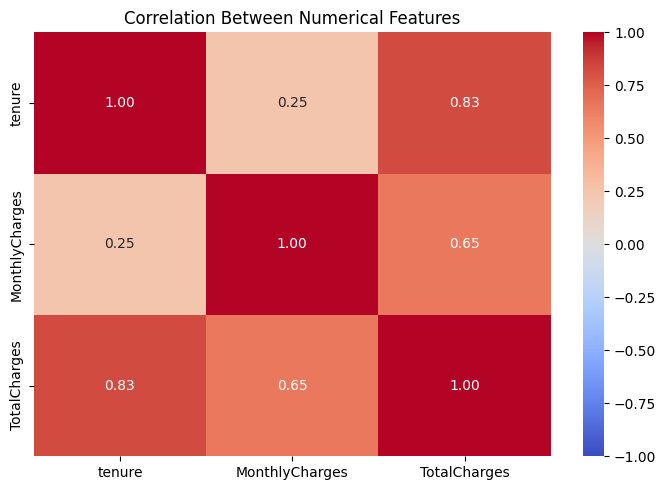

In [37]:

import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()
